# XVA Desk: CVA, DVA, FVA, KVA + Desk Attribution

A swap is never worth just its risk-free price. The bank on the other side can default, the positions have to be funded, and the regulator asks for capital against both. The XVA desk puts a price on each of those costs and decides which trading desk pays for them.

This notebook builds that desk for a multilateral development bank (MDB) that hedges its bond issuance with SOFR swaps traded with five commercial banks.

**What it does.** It prices the credit, debit, funding and capital adjustments of the book and stresses CVA for wrong-way risk. It then splits every adjustment across trades and desks with the Euler and Shapley methods.

Last, it trains a differential neural network that returns CVA and its sensitivities in microseconds.

**Data.** Today's SOFR curve and Treasury volatility (U.S. Treasury, FRED), plus ICE BofA corporate option-adjusted spreads by rating (FRED: AAA, AA, A, BBB), turned into hazard rates.

**Methods.** Hull–White Monte Carlo with pathwise discounting, and CVA, DVA, FCA/FBA and KVA (CCR capital plus BA-CVA) on discounted exposure profiles. Wrong-way risk comes from a default intensity that moves with rates.

The allocation uses Euler and Shapley. The neural pricer follows differential machine learning (Huge & Savine, 2020): it trains on single-path payoffs together with their pathwise derivatives, computed by automatic differentiation in PyTorch.

**Key output.** An XVA table by counterparty and by desk, the wrong-way risk multiplier as a function of correlation, and a comparison of Euler, Shapley and stand-alone allocation.

It also delivers a neural CVA pricer whose rate, vol and credit deltas are checked against brute-force Monte Carlo.

## 1. What an XVA desk adds

An exposure engine answers the question "how much could we lose?". The XVA desk asks a different one: **what does that risk cost, and who pays for it?**

Every derivative is first priced as if nobody could default, and then adjusted:

| Adjustment | Formula (discrete, independent defaults) | Meaning |
|---|---|---|
| **CVA** | $(1-R_c)\sum_i \mathbb E\big[D_{t_i}V^+_{t_i}\big]\,\big(S_c(t_{i-1})-S_c(t_i)\big)$ | expected loss if the counterparty defaults |
| **DVA** | $(1-R_o)\sum_i \mathbb E\big[D_{t_i}V^-_{t_i}\big]\,\big(S_o(t_{i-1})-S_o(t_i)\big)$ | the same, seen from our own default (a benefit) |
| **FCA / FBA** | $\sum_i s_F\,\Delta t\;\mathbb E\big[D_{t_i}V^{\pm}_{t_i}\big]\,S_c(t_i)S_o(t_i)$ | cost of funding positive uncollateralised exposure, or benefit of negative |
| **KVA** | $h\sum_i \mathbb E[K_{t_i}]\,P(0,t_i)\,\Delta t$ | cost of holding regulatory capital at hurdle rate $h$ |

Here $D_t$ is the pathwise SOFR discount factor and $S(t)=e^{-\lambda t}$ the survival probability. The hazard rate comes from a credit spread $s$ as $\lambda=s/(1-R)$.

An AAA development bank borrows almost at SOFR, so its DVA and FVA are small and **CVA and KVA dominate**. Wrong-way risk matters when a bank's credit gets worse in the same scenarios in which the MDB's exposure to it grows.

**Capital.** CCR capital is $8\%\times RW_c\times\text{EAD}_c(t)$, with EAD $=1.4\times$ the forward one-year average of EE (IMM style). CVA capital uses the reduced basic approach,

$$
K_{\text{BA-CVA}} = DS\,\sqrt{\Big(\rho\sum_c SCVA_c\Big)^2+(1-\rho^2)\sum_c SCVA_c^2},\qquad SCVA_c=\tfrac{1}{\alpha}RW_c\,M_c\,\text{EAD}_c\,DF_c ,
$$

with $DS=0.65$, $\rho=0.5$ and $RW_c = 5\%$ for investment-grade financials. The discount factor is $DF_c=(1-e^{-0.05M})/(0.05M)$, and $M_c$ is the notional-weighted remaining maturity of the trades still alive.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import torch

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import QuantLib as ql
from itertools import combinations
from math import factorial
from scipy.optimize import least_squares

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

N_PATHS = 5_000
DT = 1 / 12
# fixed seed: the reference swap book is reproducible
SEED = 42
RECOVERY = 0.40  # counterparties and own
# MDB unsecured funding over SOFR (AAA supranationals fund close to SOFR)
FUNDING_SPREAD_BP = 5
HURDLE = 0.10  # cost of capital for KVA
RATINGS = {
    "Bank A": "AA",
    "Bank B": "A",
    "Bank C": "A",
    "Bank D": "BBB",
    "Bank E": "AA",
}
OWN_RATING = "AAA"
# bank exposures, standardised (ECRA)
CCR_RW = {"AA": 0.20, "A": 0.30, "BBB": 0.50}
BACVA_RW, BACVA_RHO, BACVA_DS = 0.05, 0.50, 0.65
TORCH_DTYPE = torch.float64
torch.set_num_threads(max(1, (os.cpu_count() or 4) // 2))

print(
    f"QuantLib {ql.__version__} · torch {torch.__version__} (CPU) · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

QuantLib 1.44 · torch 2.14.1+cu130 (CPU) · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Market data, curve, Hull–White model and the reference swap book

In [3]:
TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
    "daily-treasury-rates.csv/{year}/all?type=daily_treasury_yield_curve"
    "&field_tdr_date_value={year}&page&_format=csv"
)


def tenor_in_years(c):
    m = re.match(r"^\s*([\d.]+)\s*(Mo|Month|Yr|Year)", c)
    return (
        None
        if not m
        else float(m.group(1)) / (12 if m.group(2).startswith("Mo") else 1)
    )


def fetch_treasury_par():
    year = dt.date.today().year
    raw = pd.read_csv(
        io.StringIO(
            requests.get(
                TREASURY_URL.format(year=year),
                headers=BROWSER_HEADERS,
                timeout=30,
            ).text
        )
    )
    if raw.empty:
        raw = pd.read_csv(
            io.StringIO(
                requests.get(
                    TREASURY_URL.format(year=year - 1),
                    headers=BROWSER_HEADERS,
                    timeout=30,
                ).text
            )
        )
    raw["date"] = pd.to_datetime(raw["Date"], format="%m/%d/%Y")
    cols = {
        c: tenor_in_years(c)
        for c in raw.columns
        if tenor_in_years(c) is not None
    }
    long = raw.melt(
        id_vars="date",
        value_vars=list(cols),
        var_name="column",
        value_name="par_yield",
    )
    long["tenor"] = long["column"].map(cols)
    return long[["date", "tenor", "par_yield"]].dropna()


par_curves = cached("treasury_par_curves", fetch_treasury_par).pivot(
    index="date", columns="tenor", values="par_yield"
)
EVAL_DATE = par_curves.index.max()
par_today = par_curves.loc[EVAL_DATE].dropna()

VOL_SERIES = {
    "DGS1": 1,
    "DGS2": 2,
    "DGS3": 3,
    "DGS5": 5,
    "DGS7": 7,
    "DGS10": 10,
    "DGS20": 20,
    "DGS30": 30,
}


def fetch_vol_history():
    frames = [
        pd.DataFrame({"date": s.index, "tenor": tenor, "yield": s.values})
        for sid, tenor in VOL_SERIES.items()
        for s in [
            fred.get_series(
                sid, observation_start=EVAL_DATE - pd.Timedelta(days=3 * 365)
            ).dropna()
        ]
    ]
    sofr = fred.get_series(
        "SOFR", observation_start=EVAL_DATE - pd.Timedelta(days=30)
    ).dropna()
    frames.append(
        pd.DataFrame({"date": sofr.index, "tenor": 0.0, "yield": sofr.values})
    )
    return pd.concat(frames, ignore_index=True)


hist = (
    cached("fred_vol_history", fetch_vol_history)
    .pivot(index="date", columns="tenor", values="yield")
    .sort_index()
)
SOFR_TODAY = hist[0.0].dropna().iloc[-1] / 100
yields_hist = hist.drop(columns=0.0).dropna()

# --- Treasury zero curve with QuantLib, then SOFR = Treasury zero + swap
# spread
today = EVAL_DATE.normalize()
ql_today = ql.Date(today.day, today.month, today.year)
ql.Settings.instance().evaluationDate = ql_today
US_GOVT = ql.UnitedStates(ql.UnitedStates.GovernmentBond)
helpers, bond_dc = [], ql.ActualActual(ql.ActualActual.Bond)
for tenor, par_yield in par_today.items():
    y = par_yield / 100
    period = (
        ql.Period(int(round(tenor * 52)), ql.Weeks)
        if tenor < 1
        else ql.Period(int(round(tenor * 12)), ql.Months)
    )
    freq, cpns, px = (
        (ql.Once, [0.0], 100 / (1 + y / 2) ** (2 * tenor))
        if tenor <= 1
        else (ql.Semiannual, [y], 100.0)
    )
    sched = ql.Schedule(
        ql_today,
        US_GOVT.advance(ql_today, period),
        ql.Period(freq),
        US_GOVT,
        ql.Unadjusted,
        ql.Unadjusted,
        ql.DateGeneration.Backward,
        False,
    )
    helpers.append(
        ql.FixedRateBondHelper(
            ql.QuoteHandle(ql.SimpleQuote(px)), 0, 100.0, sched, cpns, bond_dc
        )
    )
ust_curve = ql.PiecewiseConvexMonotoneForward(
    ql_today, helpers, ql.Actual365Fixed()
)
ust_curve.enableExtrapolation()

FINE_T = np.linspace(0, 32, 32 * 365 + 1)
ust_z = np.array(
    [ust_curve.zeroRate(max(t, 1e-4), ql.Continuous).rate() for t in FINE_T]
)
# SOFR OIS minus Treasury par (bp): an explicit, documented swap-spread
# assumption
SWAP_SPREAD_BP = {2: -15, 3: -20, 5: -25, 7: -30, 10: -40, 20: -65, 30: -75}
spread_curve = np.interp(
    FINE_T, list(SWAP_SPREAD_BP), np.array(list(SWAP_SPREAD_BP.values())) / 1e4
)


class DiscountCurve:
    """
    A SOFR discount curve stored as continuous zero rates on a fine daily grid.
    """

    def __init__(self, zero):
        self.zero = np.asarray(zero, dtype=float)
        self.log_df = -self.zero * FINE_T

    def P0(self, t):
        """Discount factor P^M(0, t)."""
        return np.exp(np.interp(t, FINE_T, self.log_df))

    def f0(self, t, h=1e-4):
        """Instantaneous forward rate f^M(0, t)."""
        lo = np.maximum(np.asarray(t) - h, 0)
        return -(np.log(self.P0(np.asarray(t) + h)) - np.log(self.P0(lo))) / (
            np.asarray(t) + h - lo
        )

    def zero_rate(self, t):
        return np.interp(t, FINE_T, self.zero)

    def shifted(self, shift):
        """
        New curve with zero rates moved by `shift` (decimal): a number or an
        array on FINE_T.
        """
        return DiscountCurve(self.zero + shift)


CURVE = DiscountCurve(ust_z + spread_curve)
print(
    f"Evaluation date {today:%Y-%m-%d} · SOFR fixing {SOFR_TODAY*100:.2f}% ·"
    f" SOFR zero 2Y {CURVE.zero_rate(2)*100:.2f}% / 10Y"
    f" {CURVE.zero_rate(10)*100:.2f}%"
)

Evaluation date 2026-10-16 · SOFR fixing 3.88% · SOFR zero 2Y 4.54% / 10Y 4.66%


In [4]:
# bp per year, by tenor
realised_vol_bp = yields_hist.diff().dropna().std() * np.sqrt(252) * 100
vol_tenors = realised_vol_bp.index.to_numpy(dtype=float)


def model_vol_bp(params, tau):
    a, sigma = params
    return sigma * (1 - np.exp(-a * tau)) / (a * tau) * 1e4


fit = least_squares(
    lambda p: model_vol_bp(p, vol_tenors) - realised_vol_bp.values,
    x0=[0.05, 0.01],
    bounds=([1e-3, 1e-4], [1.0, 0.05]),
)
A_HW, SIGMA_HW = fit.x
print(
    "Hull–White calibrated to 3 years of realised Treasury volatility: a ="
    f" {A_HW:.4f}, sigma = {SIGMA_HW*1e4:.1f} bp/yr (fit RMSE"
    f" {np.sqrt(np.mean(fit.fun**2)):.1f} bp)"
)

Hull–White calibrated to 3 years of realised Treasury volatility: a = 0.0047, sigma = 86.7 bp/yr (fit RMSE 8.7 bp)


In [5]:
class HullWhite:
    """
    Hull–White 1F (G1++ form): r_t = x_t + phi(t), fitted exactly to `curve`.
    """

    def __init__(self, curve, a, sigma):
        self.curve, self.a, self.sigma = curve, a, sigma

    def B(self, t, T):
        return (1 - np.exp(-self.a * (T - t))) / self.a

    def V(self, t, T):
        a, tau = self.a, T - t
        return (
            self.sigma**2
            / a**2
            * (
                tau
                + 2 / a * np.exp(-a * tau)
                - np.exp(-2 * a * tau) / (2 * a)
                - 3 / (2 * a)
            )
        )

    def simulate(self, times, n_paths, seed):
        """
        Exact OU simulation on any increasing grid that starts at 0; also
        integrates r for SOFR accrual.
        """
        times = np.asarray(times, dtype=float)
        rng = np.random.default_rng(seed)
        x = np.zeros((n_paths, len(times)))
        for j in range(1, len(times)):
            d = times[j] - times[j - 1]
            sd = self.sigma * np.sqrt(
                (1 - np.exp(-2 * self.a * d)) / (2 * self.a)
            )
            x[:, j] = x[:, j - 1] * np.exp(
                -self.a * d
            ) + sd * rng.standard_normal(n_paths)
        phi = (
            self.curve.f0(times)
            + self.sigma**2
            / (2 * self.a**2)
            * (1 - np.exp(-self.a * times)) ** 2
        )
        r = x + phi
        int_r = np.concatenate(
            [
                np.zeros((n_paths, 1)),
                np.cumsum(
                    0.5 * (r[:, 1:] + r[:, :-1]) * np.diff(times), axis=1
                ),
            ],
            axis=1,
        )
        return {
            "times": times,
            "x": x,
            "int_r": int_r,
            "index": {round(t, 8): j for j, t in enumerate(times)},
        }

    def zcb(self, t, T, x_t):
        """
        P(t, T) on every path (x_t: paths) for every maturity in T (m) → paths
        × m.
        """
        T = np.atleast_1d(T)
        P0 = self.curve.P0
        log_a = np.log(P0(T) / P0(t)) + 0.5 * (
            self.V(t, T) - self.V(0.0, T) + self.V(0.0, t)
        )
        return np.exp(log_a[None, :] - np.outer(x_t, self.B(t, T)))


def par_rate(curve, first_pay, n):
    """
    Par fixed rate today for annual payments at first_pay, first_pay+1, ...;
    the part of the current
    period already elapsed accrues at today's SOFR fixing, exactly as in the
    simulation.
    """
    pay = first_pay + np.arange(n)
    start = first_pay - 1
    float_leg = (
        (np.exp(SOFR_TODAY * (-start)) - curve.P0(pay[-1]))
        if start < 0
        else curve.P0(start) - curve.P0(pay[-1])
    )
    return float_leg / curve.P0(pay).sum()


def swap_legs(first_pay, n_pay, hw, sim, dtype=np.float32, cutoff=None):
    """
    Annuity and floating-leg value per unit notional of an annual-fixed vs
    compounded-SOFR swap,
    on every path and simulation date (paths × dates). Value to the fixed
    receiver = K·annuity − float.
    `cutoff` (optional, one time per grid date) drops cash flows paid on or
    before it: used to value at
    t−MPoR only the flows still outstanding at t (both parties keep paying
    during the margin period).
    """
    times, x, int_r, index = sim["times"], sim["x"], sim["int_r"], sim["index"]
    cutoff = times if cutoff is None else np.maximum(cutoff, times)
    pay = first_pay + np.arange(n_pay)
    annuity = np.zeros(x.shape, dtype=dtype)
    float_leg = np.zeros(x.shape, dtype=dtype)
    for j, t in enumerate(times):
        live = pay > cutoff[j] + 1e-9
        if not live.any():
            # matured (or all flows paid by the cutoff)
            continue
        rem = pay[live]
        # start of the accrual period of the next flow
        start = rem[0] - 1.0
        # period starts after t (only with a cutoff)
        if start > t + 1e-9:
            p = hw.zcb(t, np.concatenate([[start], rem]), x[:, j])
            annuity[:, j] = p[:, 1:].sum(axis=1)
            float_leg[:, j] = p[:, 0] - p[:, -1]
            continue
        p = hw.zcb(t, rem, x[:, j])
        accrual = (
            np.exp(int_r[:, j] - int_r[:, index[round(start, 8)]])
            if start >= 0
            else np.exp(SOFR_TODAY * (-start) + int_r[:, j])
        )
        annuity[:, j] = p.sum(axis=1)
        # Compounded SOFR: the running coupon is worth (SOFR accrued so far) −
        # P(t, T_next), because the compounding still to come up to T_next is
        # worth exactly 1 today. Summing the remaining coupons telescopes to:
        # accrued factor − P(t, T_n).
        float_leg[:, j] = accrual - p[:, -1]
    return annuity, float_leg


def revalue_book(book, hw, sim, cutoff=None):
    """
    Values to us (USD mm) of every swap in `book` on every path and date →
    trades × paths × dates.
    """
    out = np.zeros((len(book), *sim["x"].shape), dtype=np.float32)
    for i, tr in enumerate(book.itertuples()):
        ann, flt = swap_legs(tr.first_pay, tr.n_pay, hw, sim, cutoff=cutoff)
        out[i] = tr.omega * (tr.fixed_rate * ann - flt) * tr.notional_mm
    return out


def exposure_metrics(v, times, q=0.975):
    """
    v: paths × monthly dates (USD mm) → EE, ENE, PFE profiles and the Basel
    1-year scalars EPE and EEPE
    (standard definitions: averages over the monthly grid points of the first
    year).
    """
    pos = np.maximum(v, 0)
    ee = pos.mean(axis=0)
    one_year = times <= 1.0 + 1e-9
    eff_ee = np.maximum.accumulate(ee)
    return {
        "EE": ee,
        "ENE": np.minimum(v, 0).mean(axis=0),
        "PFE": np.quantile(pos, q, axis=0),
        "EPE": ee[one_year].mean(),
        "EEPE": eff_ee[one_year].mean(),
    }

In [6]:
# The reference swap book, generated with a fixed seed and documented rules so
# every number is reproducible
rng = np.random.default_rng(42)
COUNTERPARTIES = ["Bank A", "Bank B", "Bank C", "Bank D", "Bank E"]
PFE_LIMITS = {
    "Bank A": 250,
    "Bank B": 80,
    "Bank C": 150,
    "Bank D": 180,
    "Bank E": 100,
}
trades = []
for i in range(25):
    # next payment in 1–12 months (month-aligned)
    first_pay = rng.integers(1, 13) / 12
    n_pay = int(rng.choice([2, 3, 5, 7, 10, 10, 15, 20, 30]))
    seasoned = rng.random() < 0.6
    k_par = par_rate(CURVE, first_pay, n_pay)
    fixed = k_par + (rng.normal(0, 0.0075) if seasoned else 0.0)
    trades.append({
        "trade_id": f"IRS-{i+1:03d}",
        "counterparty": COUNTERPARTIES[i % 5],
        "direction": rng.choice(["receive fixed", "pay fixed"]),
        "notional_mm": float(rng.choice([25, 50, 100, 150, 250, 400])),
        "first_pay": first_pay,
        "n_pay": n_pay,
        "fixed_rate": fixed,
        "par_rate": k_par,
        "maturity_y": first_pay + n_pay - 1,
    })
book = pd.DataFrame(trades)
book["omega"] = np.where(book["direction"] == "receive fixed", 1.0, -1.0)

HORIZON = book["maturity_y"].max()
TIME = np.round(np.arange(0, HORIZON + DT / 2, DT), 10)
hw = HullWhite(CURVE, A_HW, SIGMA_HW)
# fixed seed: reproducible paths
sim = hw.simulate(TIME, N_PATHS, seed=SEED + 1)
# trades × paths × dates
values = revalue_book(book, hw, sim)
# pathwise SOFR discount factor
DISC = np.exp(-sim["int_r"]).astype(np.float32)
netted = {
    cp: values[(book["counterparty"] == cp).to_numpy()].sum(axis=0)
    for cp in COUNTERPARTIES
}
print(
    f"Reference book: {len(book)} swaps, {len(COUNTERPARTIES)} banks · MtM"
    f" today {values[:, :, 0].mean(axis=1).sum():+.1f}mm"
)

Reference book: 25 swaps, 5 banks · MtM today -18.5mm


## 4. Credit curves from market spreads

The desk would normally use each bank's CDS spread, but those prices are not public. The ICE BofA option-adjusted spreads of the U.S. corporate index by rating are a reasonable public stand-in, and the AAA index plays the role of the MDB's own credit.

Hazard rates follow the credit-triangle approximation $\lambda = s/(1-R)$.

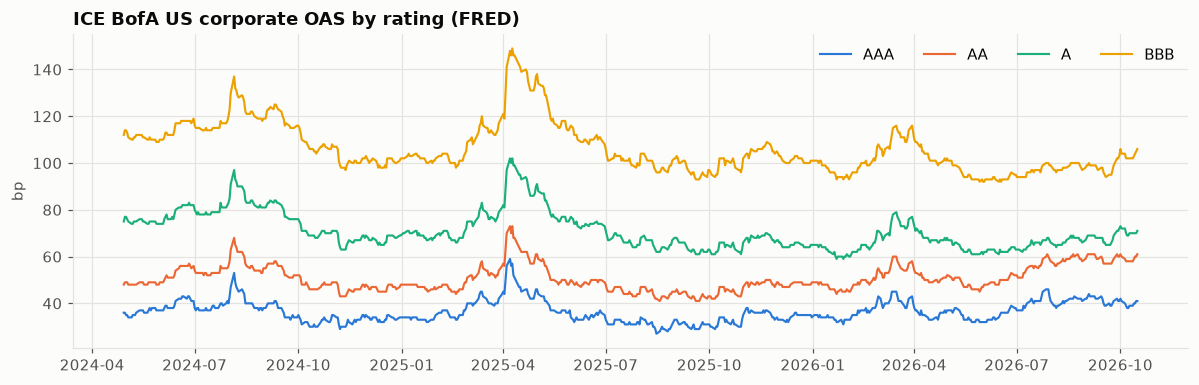

,OAS (bp),hazard λ (%),5y PD (%)
rating,,,
A,71.00,1.18,5.75
AA,61.00,1.02,4.96
AAA,41.00,0.68,3.36
BBB,106.00,1.77,8.45


In [7]:
OAS_SERIES = {
    "AAA": "BAMLC0A1CAAA",
    "AA": "BAMLC0A2CAA",
    "A": "BAMLC0A3CA",
    "BBB": "BAMLC0A4CBBB",
}


def fetch_oas():
    return pd.concat([
        pd.DataFrame({"date": s.index, "rating": r, "oas": s.values})
        for r, sid in OAS_SERIES.items()
        # FRED keeps ~3y of ICE data
        for s in [
            fred.get_series(
                sid, observation_start=EVAL_DATE - pd.Timedelta(days=900)
            ).dropna()
        ]
    ])


oas = (
    cached("fred_oas_by_rating", fetch_oas)
    .pivot(index="date", columns="rating", values="oas")
    .sort_index()
)
# decimal
SPREAD = oas.ffill().iloc[-1] / 100
HAZARD = SPREAD / (1 - RECOVERY)
credit = pd.DataFrame({
    "OAS (bp)": SPREAD * 1e4,
    "hazard λ (%)": HAZARD * 100,
    "5y PD (%)": (1 - np.exp(-5 * HAZARD)) * 100,
})
lam = {cp: HAZARD[RATINGS[cp]] for cp in COUNTERPARTIES}
lam_own = HAZARD[OWN_RATING]

fig, ax = plt.subplots(figsize=(11, 3.6))
for r, color in zip(OAS_SERIES, PALETTE):
    ax.plot(oas.index, oas[r] * 100, color=color, lw=1.4, label=r)
ax.set_title("ICE BofA US corporate OAS by rating (FRED)")
ax.set_ylabel("bp")
ax.legend(ncol=4)
plt.tight_layout()
save_fig(fig, "01_credit_spreads_by_rating")
plt.show()
credit.round(3)

## 5. XVA by counterparty

Every expectation here uses the pathwise discount factor, so exposure in a high-rate scenario is discounted more heavily.

That is the right measure for pricing. Limits are a different job and use the undiscounted EE.

In [8]:
dt_ = np.diff(TIME, prepend=0.0)
S_own = np.exp(-lam_own * TIME)
P0_t = CURVE.P0(TIME)
sF = FUNDING_SPREAD_BP / 1e4


def discounted_profiles(v):
    return (DISC * np.maximum(v, 0)).mean(axis=0), (
        DISC * np.minimum(v, 0)
    ).mean(axis=0)


def capital_profile(ee, trades_cp, rating):
    """
    Expected CCR and BA-CVA stand-alone inputs at each date from an
    (undiscounted) EE profile.
    """
    maturity = trades_cp["maturity_y"].max()
    window = int(round(1 / DT))
    # forward 1-year average
    fwd_ee = np.array([ee[j : j + window + 1].mean() for j in range(len(ee))])
    # non-increasing EEPE proxy
    ead = 1.4 * np.maximum.accumulate(fwd_ee[::-1])[::-1] * (TIME < maturity)
    # Effective maturity: notional-weighted remaining life of the trades still
    # alive at each date
    rem = np.clip(
        trades_cp["maturity_y"].to_numpy()[:, None] - TIME[None, :], 0, None
    )
    w = trades_cp["notional_mm"].to_numpy()[:, None] * (rem > 0)
    M = np.clip(
        (w * rem).sum(axis=0) / np.maximum(w.sum(axis=0), 1e-12), 1e-6, None
    )
    df = (1 - np.exp(-0.05 * M)) / (0.05 * M)
    k_ccr = 0.08 * CCR_RW[rating] * ead
    scva = BACVA_RW * M * ead * df / 1.4
    return k_ccr, scva


xva_rows, ee_disc, ne_disc, cap = [], {}, {}, {}
for cp in COUNTERPARTIES:
    v = netted[cp]
    pe, ne = discounted_profiles(v)
    ee_disc[cp], ne_disc[cp] = pe, ne
    S_c = np.exp(-lam[cp] * TIME)
    dPD_c = np.r_[0.0, S_c[:-1] - S_c[1:]]
    dPD_o = np.r_[0.0, S_own[:-1] - S_own[1:]]
    cva = (1 - RECOVERY) * np.sum(pe * dPD_c)
    dva = (1 - RECOVERY) * np.sum(-ne * dPD_o)
    fca = np.sum(sF * dt_ * pe * S_c * S_own)
    fba = np.sum(sF * dt_ * -ne * S_c * S_own)
    cap[cp] = capital_profile(
        np.maximum(v, 0).mean(axis=0),
        book[book["counterparty"] == cp],
        RATINGS[cp],
    )
    xva_rows.append({
        "counterparty": cp,
        "rating": RATINGS[cp],
        "MtM": v[:, 0].mean(),
        "CVA": -cva,
        "DVA": dva,
        "FCA": -fca,
        "FBA": fba,
    })
xva = pd.DataFrame(xva_rows).set_index("counterparty")

# KVA: CCR capital is additive across banks; BA-CVA aggregates with ρ,
# allocated back by Euler at each date banks × dates
scva = np.array([cap[cp][1] for cp in COUNTERPARTIES])
k_red = np.sqrt(
    (BACVA_RHO * scva.sum(axis=0)) ** 2
    + (1 - BACVA_RHO**2) * (scva**2).sum(axis=0)
)
euler_w = np.divide(
    BACVA_RHO**2 * scva.sum(axis=0) + (1 - BACVA_RHO**2) * scva,
    k_red,
    out=np.zeros_like(scva),
    where=k_red > 0,
)
# sums to DS × K_reduced
k_cva_alloc = BACVA_DS * scva * euler_w
for i, cp in enumerate(COUNTERPARTIES):
    xva.loc[cp, "KVA (CCR)"] = -HURDLE * np.sum(cap[cp][0] * P0_t * dt_)
    xva.loc[cp, "KVA (CVA)"] = -HURDLE * np.sum(k_cva_alloc[i] * P0_t * dt_)
XVA_COLS = ["CVA", "DVA", "FCA", "FBA", "KVA (CCR)", "KVA (CVA)"]
xva["total XVA"] = xva[XVA_COLS].sum(axis=1)
xva.loc["Total"] = xva.sum(numeric_only=True)
xva.loc["Total", "rating"] = ""
xva.round(3)

,rating,MtM,CVA,DVA,FCA,FBA,KVA (CCR),KVA (CVA),total XVA
counterparty,,,,,,,,,
Bank A,AA,14.13,-2.11,1.33,-0.17,0.15,-0.77,-6.07,-7.63
Bank B,A,-44.94,-0.21,1.38,-0.01,0.16,-0.15,-0.31,0.86
Bank C,A,11.71,-1.31,0.49,-0.09,0.05,-0.61,-3.08,-4.54
Bank D,BBB,6.47,-3.30,1.13,-0.14,0.11,-2.02,-9.01,-13.24
Bank E,AA,-5.84,-0.85,0.82,-0.07,0.09,-0.30,-1.70,-2.01
Total,,-18.47,-7.78,5.15,-0.47,0.56,-3.85,-20.17,-26.56


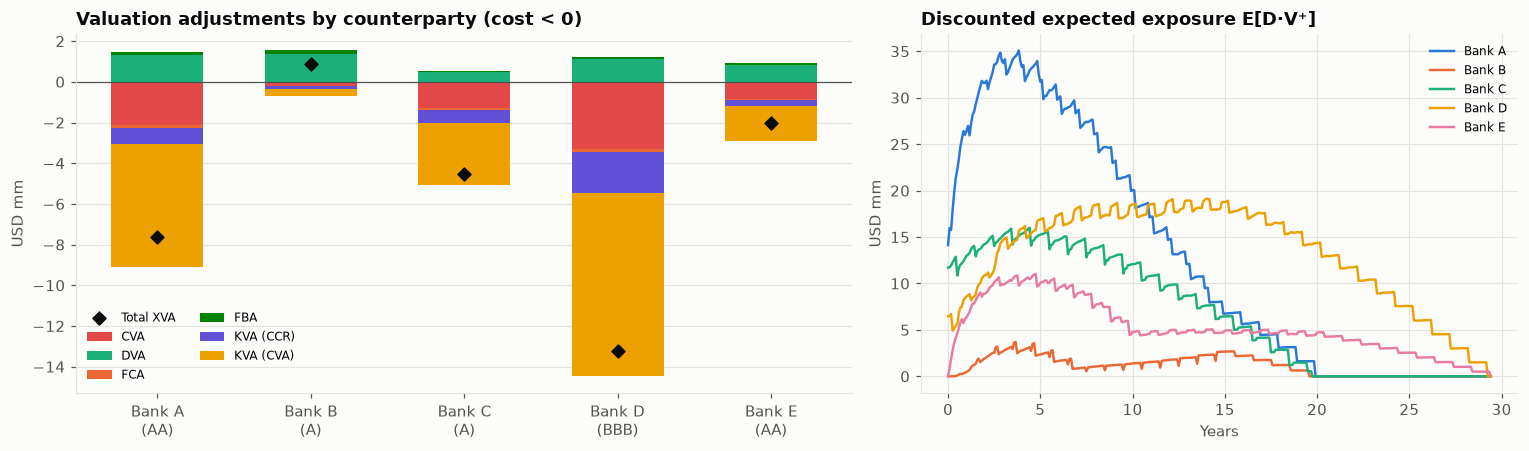

In [9]:
# --- Chart 2: XVA by counterparty
fig, axes = plt.subplots(
    1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.3, 1]}
)
ax = axes[0]
x_pos = np.arange(len(COUNTERPARTIES))
pos_bottom, neg_bottom = np.zeros(len(x_pos)), np.zeros(len(x_pos))
for col, color in zip(
    XVA_COLS,
    [PALETTE[7], PALETTE[2], PALETTE[1], PALETTE[5], PALETTE[6], PALETTE[3]],
):
    val = xva.loc[COUNTERPARTIES, col].to_numpy()
    bottom = np.where(val >= 0, pos_bottom, neg_bottom)
    ax.bar(x_pos, val, bottom=bottom, color=color, label=col, width=0.6)
    pos_bottom += np.maximum(val, 0)
    neg_bottom += np.minimum(val, 0)
ax.scatter(
    x_pos,
    xva.loc[COUNTERPARTIES, "total XVA"],
    color=INK,
    marker="D",
    zorder=3,
    label="Total XVA",
)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xticks(x_pos, [f"{c}\n({RATINGS[c]})" for c in COUNTERPARTIES])
ax.set_title("Valuation adjustments by counterparty (cost < 0)")
ax.set_ylabel("USD mm")
ax.legend(fontsize=8, ncol=2)
ax.grid(axis="x", visible=False)
ax = axes[1]
for cp, color in zip(COUNTERPARTIES, PALETTE):
    ax.plot(TIME, ee_disc[cp], color=color, lw=1.6, label=cp)
ax.set_title("Discounted expected exposure E[D·V⁺]")
ax.set_xlabel("Years")
ax.set_ylabel("USD mm")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "02_xva_by_counterparty")
plt.show()

## 6. Wrong-way risk

The independent model assumes a bank's chance of default has nothing to do with rates. In practice, deep rate cuts tend to come with financial stress.

If the MDB **receives fixed** from a bank, its exposure is largest exactly when rates have fallen, which is also when banks are weakest.

To capture this, each bank's hazard rate becomes random and moves with the rate factor:

$$
\lambda_t=\lambda_0\exp\!\big(\beta\,z_t-\tfrac12\beta^2\big),\qquad z_t=x_t/\mathrm{sd}(x_t).
$$

This keeps $\mathbb E[\lambda_t]=\lambda_0$, so the average credit quality does not change. A negative $\beta$ means credit worsens when rates fall.

CVA becomes $(1-R)\sum_i\mathbb E\big[D_{t_i}V^+_{t_i}(S_{t_{i-1}}-S_{t_i})\big]$, with pathwise survival $S_t=e^{-\int_0^t\lambda_u du}$.

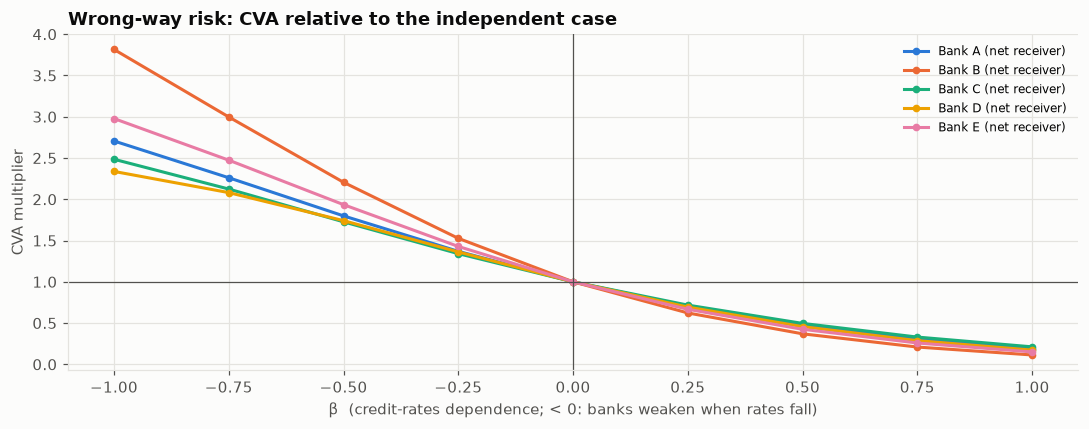

,-1.00,-0.75,-0.50,-0.25,0.00,0.25,0.50,0.75,1.00
Bank A,2.71,2.26,1.80,1.37,1.00,0.70,0.47,0.31,0.19
Bank B,3.82,3.00,2.21,1.53,1.00,0.62,0.37,0.21,0.11
Bank C,2.48,2.12,1.73,1.34,1.00,0.72,0.50,0.33,0.21
Bank D,2.34,2.08,1.74,1.36,1.00,0.69,0.46,0.29,0.17
Bank E,2.98,2.47,1.94,1.43,1.00,0.67,0.42,0.26,0.15


In [10]:
z = sim["x"] / np.maximum(sim["x"].std(axis=0, keepdims=True), 1e-12)
BETAS = np.linspace(-1.0, 1.0, 9)
wwr = {}
for cp in COUNTERPARTIES:
    pe_path = DISC * np.maximum(netted[cp], 0)
    out = []
    for beta in BETAS:
        lam_t = lam[cp] * np.exp(beta * z - 0.5 * beta**2)
        cum = np.concatenate(
            [
                np.zeros((N_PATHS, 1)),
                np.cumsum(0.5 * (lam_t[:, 1:] + lam_t[:, :-1]) * DT, axis=1),
            ],
            axis=1,
        )
        S = np.exp(-cum)
        dPD = np.concatenate(
            [np.zeros((N_PATHS, 1)), S[:, :-1] - S[:, 1:]], axis=1
        )
        out.append((1 - RECOVERY) * (pe_path * dPD).mean(axis=0).sum())
    wwr[cp] = np.array(out)
wwr = pd.DataFrame(wwr, index=np.round(BETAS, 2))
wwr_mult = wwr / wwr.loc[0.0]

net_dir = (
    book.assign(dv=book["omega"] * book["notional_mm"] * book["maturity_y"])
    .groupby("counterparty")["dv"]
    .sum()
)
fig, ax = plt.subplots(figsize=(10, 4))
for cp, color in zip(COUNTERPARTIES, PALETTE):
    tag = "net receiver" if net_dir[cp] > 0 else "net payer"
    ax.plot(
        BETAS, wwr_mult[cp], "o-", color=color, ms=4, label=f"{cp} ({tag})"
    )
ax.axhline(1, color=INK_2, lw=0.8)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_title("Wrong-way risk: CVA relative to the independent case")
ax.set_xlabel(
    "β  (credit-rates dependence; < 0: banks weaken when rates fall)"
)
ax.set_ylabel("CVA multiplier")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "03_wrong_way_risk")
plt.show()
wwr_mult.round(2).T

## 7. Who pays? Euler, Shapley and stand-alone allocation

XVA is computed for each netting set, but trades are booked by desks, and each desk wants to see its own charge. There are three common ways to split it:

- **Stand-alone:** each trade's XVA as if it were the only trade. It ignores netting, so the pieces add up to more than the whole.
- **Euler (marginal):** CVA is homogeneous of degree one in trade sizes, so $\text{CVA}=\sum_k w_k\,\partial\text{CVA}/\partial w_k$. The contribution of trade $k$ is $(1-R)\sum_i\Delta PD_i\,\mathbb E[D_{t_i}\mathbb 1\{V_{t_i}>0\}V^{(k)}_{t_i}]$. The pieces add up exactly, and a trade that hedges the netting set gets a negative charge.
- **Shapley:** the average marginal CVA of a trade over every order in which the trades could have been added. It is fair and additive, but it needs $2^n$ netting-set revaluations. That is cheap here because trade values are already computed.

In [11]:
def cva_of(v, cp):
    S_c = np.exp(-lam[cp] * TIME)
    dPD = np.r_[0.0, S_c[:-1] - S_c[1:]]
    return (1 - RECOVERY) * np.sum(
        (DISC * np.maximum(v, 0)).mean(axis=0) * dPD
    )


alloc_rows = []
for cp in COUNTERPARTIES:
    idx = np.flatnonzero((book["counterparty"] == cp).to_numpy())
    v_ns = values[idx].sum(axis=0)
    S_c = np.exp(-lam[cp] * TIME)
    dPD = np.r_[0.0, S_c[:-1] - S_c[1:]]
    ind = (v_ns > 0).astype(np.float32) * DISC
    total = cva_of(v_ns, cp)
    n = len(idx)
    cache = {(): 0.0}
    for size in range(1, n + 1):
        for sub in combinations(range(n), size):
            cache[sub] = cva_of(values[idx[list(sub)]].sum(axis=0), cp)
    for pos, k in enumerate(idx):
        euler = (1 - RECOVERY) * np.sum((ind * values[k]).mean(axis=0) * dPD)
        shap_k = 0.0
        others = [j for j in range(n) if j != pos]
        for size in range(n):
            w = factorial(size) * factorial(n - size - 1) / factorial(n)
            for sub in combinations(others, size):
                shap_k += w * (cache[tuple(sorted(sub + (pos,)))] - cache[sub])
        alloc_rows.append({
            "trade_id": book.loc[k, "trade_id"],
            "counterparty": cp,
            "direction": book.loc[k, "direction"],
            "notional_mm": book.loc[k, "notional_mm"],
            "maturity_y": book.loc[k, "maturity_y"],
            "stand-alone": cva_of(values[k], cp),
            "Euler": euler,
            "Shapley": shap_k,
            "netting-set CVA": total,
        })
alloc = pd.DataFrame(alloc_rows)
check = alloc.groupby("counterparty")[
    ["stand-alone", "Euler", "Shapley", "netting-set CVA"]
].agg({
    "stand-alone": "sum",
    "Euler": "sum",
    "Shapley": "sum",
    "netting-set CVA": "first",
})
check.round(4)

,stand-alone,Euler,Shapley,netting-set CVA
counterparty,,,,
Bank A,2.14,2.11,2.11,2.11
Bank B,1.75,0.21,0.21,0.21
Bank C,2.61,1.31,1.31,1.31
Bank D,4.95,3.30,3.30,3.30
Bank E,1.45,0.85,0.85,0.85


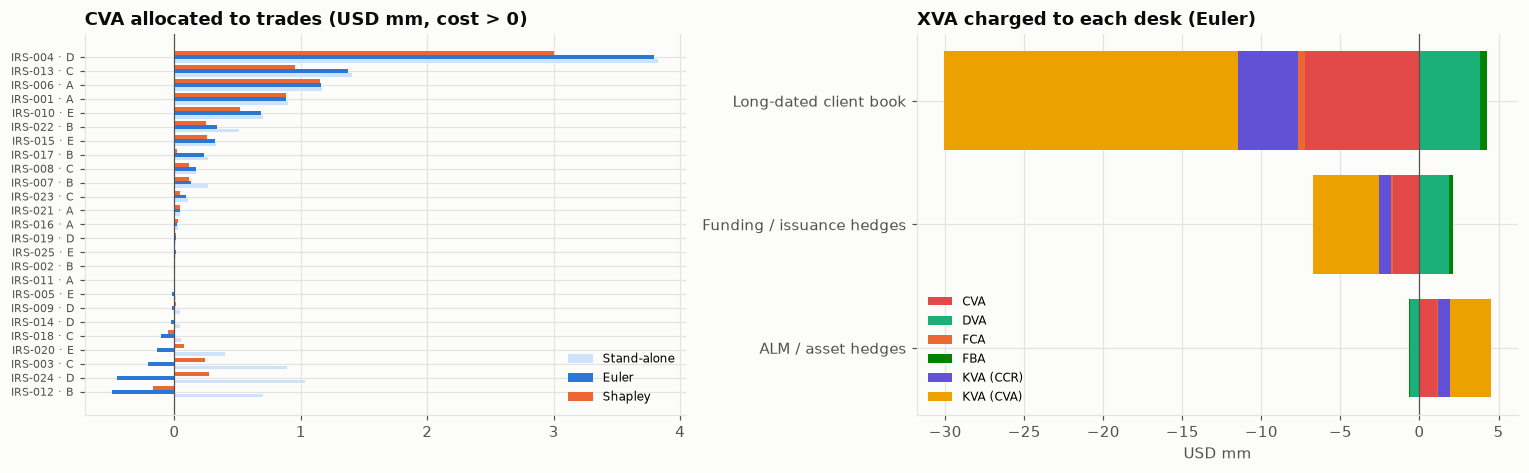

,CVA,DVA,FCA,FBA,KVA (CCR),KVA (CVA),total XVA
desk,,,,,,,
ALM / asset hedges,1.12,-0.59,0.07,-0.07,0.77,2.55,3.85
Funding / issuance hedges,-1.66,1.89,-0.13,0.22,-0.77,-4.17,-4.62
Long-dated client book,-7.25,3.85,-0.41,0.41,-3.84,-18.55,-25.79
Total,-7.78,5.15,-0.47,0.56,-3.85,-20.17,-26.56


In [12]:
# --- Desk attribution: every adjustment allocated by Euler to the trade, then
# summed by desk
DESKS = {
    "receive fixed": "Funding / issuance hedges",
    "pay fixed": "ALM / asset hedges",
}
book["desk"] = np.where(
    book["maturity_y"] >= 15,
    "Long-dated client book",
    book["direction"].map(DESKS),
)

trade_xva = []
for cp in COUNTERPARTIES:
    idx = np.flatnonzero((book["counterparty"] == cp).to_numpy())
    v_ns = values[idx].sum(axis=0)
    S_c = np.exp(-lam[cp] * TIME)
    dPD_c = np.r_[0.0, S_c[:-1] - S_c[1:]]
    dPD_o = np.r_[0.0, S_own[:-1] - S_own[1:]]
    pos_ind, neg_ind = (v_ns > 0) * DISC, (v_ns < 0) * DISC
    ee_tot = np.maximum(v_ns, 0).mean(axis=0)
    kccr_tot, kcva_tot = (
        -HURDLE * np.sum(cap[cp][0] * P0_t * dt_),
        xva.loc[cp, "KVA (CVA)"],
    )
    ee_share_sum = 0
    for k in idx:
        # Euler pieces of E[D·V⁺] and E[D·V⁻]
        pe_k = (pos_ind * values[k]).mean(axis=0)
        ne_k = (neg_ind * values[k]).mean(axis=0)
        # Euler piece of undiscounted EE (drives capital)
        ee_k = ((v_ns > 0) * values[k]).mean(axis=0)
        share = np.sum(ee_k * P0_t * dt_) / max(
            np.sum(ee_tot * P0_t * dt_), 1e-12
        )
        trade_xva.append({
            "trade_id": book.loc[k, "trade_id"],
            "desk": book.loc[k, "desk"],
            "counterparty": cp,
            "CVA": -(1 - RECOVERY) * np.sum(pe_k * dPD_c),
            "DVA": (1 - RECOVERY) * np.sum(-ne_k * dPD_o),
            "FCA": -np.sum(sF * dt_ * pe_k * S_c * S_own),
            "FBA": np.sum(sF * dt_ * -ne_k * S_c * S_own),
            "KVA (CCR)": share * kccr_tot,
            "KVA (CVA)": share * kcva_tot,
        })
trade_xva = pd.DataFrame(trade_xva)
trade_xva["total XVA"] = trade_xva[XVA_COLS].sum(axis=1)
desk_xva = trade_xva.groupby("desk")[XVA_COLS + ["total XVA"]].sum()
desk_xva.loc["Total"] = desk_xva.sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]
a = alloc.sort_values("Euler")
y_pos = np.arange(len(a))
ax.barh(
    y_pos - 0.27, a["stand-alone"], 0.27, color="#cde2fb", label="Stand-alone"
)
ax.barh(y_pos, a["Euler"], 0.27, color=PALETTE[0], label="Euler")
ax.barh(y_pos + 0.27, a["Shapley"], 0.27, color=PALETTE[1], label="Shapley")
ax.set_yticks(
    y_pos,
    [f"{t} · {c[-1]}" for t, c in zip(a["trade_id"], a["counterparty"])],
    fontsize=7,
)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_title("CVA allocated to trades (USD mm, cost > 0)")
ax.legend(fontsize=8)
ax = axes[1]
d = desk_xva.drop(index="Total")
left_p, left_n = np.zeros(len(d)), np.zeros(len(d))
for col, color in zip(
    XVA_COLS,
    [PALETTE[7], PALETTE[2], PALETTE[1], PALETTE[5], PALETTE[6], PALETTE[3]],
):
    val = d[col].to_numpy()
    ax.barh(
        d.index,
        val,
        left=np.where(val >= 0, left_p, left_n),
        color=color,
        label=col,
    )
    left_p += np.maximum(val, 0)
    left_n += np.minimum(val, 0)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_title("XVA charged to each desk (Euler)")
ax.set_xlabel("USD mm")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "04_allocation_euler_shapley_desks")
plt.show()
desk_xva.round(3)

## 8. Differential machine learning: a CVA pricer with Greeks

The desk hedges CVA, so it needs CVA **sensitivities** every day and in every risk scenario. Bump-and-revalue costs a full Monte Carlo run for each bump, which is too slow.

**Differential ML** (Huge & Savine, 2020) gets around this. The network is trained on cheap, *noisy* labels, one simulated path per sample, together with the **pathwise derivatives** of each label with respect to the inputs. Those derivatives come from automatic differentiation through the whole simulation.

The network learns the CVA function and its gradient at the same time, so its derivatives are accurate by construction.

**Inputs** $\theta=(\Delta r,\;\sigma,\;s)$: a parallel shift of the SOFR curve (±150 bp), the Hull–White volatility (50–130 bp) and the counterparty spread (30–300 bp). The netting set is Bank D. The simulation is rewritten in PyTorch so that every step can be differentiated:

$$
x_t=\sigma\,y_t\ \text{(unit OU)},\quad \log P^M_{\Delta r}(0,T)=\log P^M(0,T)-\Delta r\,T,\quad \text{CVA}_{\text{path}}=(1-R)\sum_i D_{t_i}V^+_{t_i}\big(e^{-\lambda t_{i-1}}-e^{-\lambda t_i}\big).
$$

The training set has 32,768 samples. Each one is a **single path**, so the labels are extremely noisy.

The **ground truth** for testing is brute-force Monte Carlo with 20,000 paths per point on 15 test points (7 along the rate axis, 8 random). Its deltas come from AAD on the same paths.

In [13]:
cp_dml = "Bank D"
dml_trades = book[book["counterparty"] == cp_dml].reset_index(drop=True)
J = int(round(dml_trades["maturity_y"].max() / DT))
t_grid = torch.tensor(np.arange(J + 1) * DT, dtype=TORCH_DTYPE)
# every date is a multiple of a month
LAT = np.arange(0, 12 * 32 + 1) / 12
logP_lat = torch.tensor(np.log(CURVE.P0(LAT)), dtype=TORCH_DTYPE)
f0_grid = torch.tensor(CURVE.f0(np.arange(J + 1) * DT), dtype=TORCH_DTYPE)
a = A_HW
TRADES_T = [
    dict(
        omega=float(r.omega),
        N=float(r.notional_mm),
        K=float(r.fixed_rate),
        pay=np.round((r.first_pay + np.arange(r.n_pay)) * 12).astype(int),
    )
    for r in dml_trades.itertuples()
]


def lattice(k):
    return logP_lat[torch.as_tensor(k)]


def pathwise_cva(shift, sigma, spread, normals):
    """
    Differentiable single-path CVA for every row: shift, sigma, spread are
    tensors (B,), normals (B, J).
    """
    B = shift.shape[0]
    decay = np.exp(-a * DT)
    sd = np.sqrt((1 - np.exp(-2 * a * DT)) / (2 * a))
    y = [torch.zeros(B, dtype=TORCH_DTYPE)]
    for j in range(J):
        y.append(y[-1] * decay + sd * normals[:, j])
    # (B, J+1)
    y = torch.stack(y, dim=1)
    x = sigma[:, None] * y
    phi = (
        f0_grid[None, :]
        + shift[:, None]
        + sigma[:, None] ** 2
        / (2 * a**2)
        * (1 - torch.exp(-a * t_grid[None, :])) ** 2
    )
    r = x + phi
    int_r = torch.cat(
        [
            torch.zeros(B, 1, dtype=TORCH_DTYPE),
            torch.cumsum(0.5 * (r[:, 1:] + r[:, :-1]) * DT, dim=1),
        ],
        dim=1,
    )

    # Hull–White variance term per unit sigma²
    def Vfun(t, T):
        tau = T - t
        return (
            tau
            + 2 / a * np.exp(-a * tau)
            - np.exp(-2 * a * tau) / (2 * a)
            - 3 / (2 * a)
        ) / a**2

    values = [torch.zeros(B, dtype=TORCH_DTYPE)]
    for j in range(1, J + 1):
        t = j * DT
        v_j = torch.zeros(B, dtype=TORCH_DTYPE)
        for tr in TRADES_T:
            rem = tr["pay"][tr["pay"] > j]
            if len(rem) == 0:
                continue
            T = rem / 12
            Bfac = torch.tensor(
                (1 - np.exp(-a * (T - t))) / a, dtype=TORCH_DTYPE
            )
            var = torch.tensor(
                Vfun(t, T) - Vfun(0.0, T) + Vfun(0.0, t), dtype=TORCH_DTYPE
            )
            log_p = (
                (
                    lattice(rem)
                    - shift[:, None] * torch.tensor(T, dtype=TORCH_DTYPE)
                )
                - (logP_lat[j] - shift[:, None] * t)
                + 0.5 * sigma[:, None] ** 2 * var
                - x[:, j : j + 1] * Bfac
            )
            p = torch.exp(log_p)
            start = rem[0] - 12
            accrual = (
                torch.exp(int_r[:, j] - int_r[:, start])
                if start >= 0
                else torch.exp(SOFR_TODAY * (-start / 12) + int_r[:, j])
            )
            v_j = v_j + tr["omega"] * tr["N"] * (
                tr["K"] * p.sum(dim=1) - (accrual - p[:, -1])
            )
        values.append(v_j)
    values = torch.stack(values, dim=1)
    lam_ = spread / (1 - RECOVERY)
    surv = torch.exp(-lam_[:, None] * t_grid[None, :])
    dpd = surv[:, :-1] - surv[:, 1:]
    return (1 - RECOVERY) * (
        torch.exp(-int_r[:, 1:]) * torch.clamp(values[:, 1:], min=0) * dpd
    ).sum(dim=1)


# shift, sigma, spread (decimals)
LOW = np.array([-0.015, 0.0050, 0.0030])
HIGH = np.array([0.015, 0.0130, 0.0300])
NAMES = ["shift", "sigma", "spread"]


def to_unit(theta):
    return 2 * (theta - torch.tensor(LOW)) / torch.tensor(HIGH - LOW) - 1


# --- Sanity check: torch pricer = NumPy engine at today's parameters
gen = torch.Generator().manual_seed(SEED)
th0 = torch.tensor(
    [[0.0, SIGMA_HW, SPREAD[RATINGS[cp_dml]]]], dtype=TORCH_DTYPE
).repeat(5_000, 1)
with torch.no_grad():
    cva_paths = pathwise_cva(
        th0[:, 0],
        th0[:, 1],
        th0[:, 2],
        torch.randn(5_000, J, generator=gen, dtype=TORCH_DTYPE),
    )
cva_torch, cva_se = cva_paths.mean().item(), cva_paths.std().item() / np.sqrt(
    len(cva_paths)
)
print(
    f"{cp_dml} CVA: PyTorch pricer {cva_torch:.3f}mm ±"
    f" {1.96 * cva_se:.3f} (95% MC band) vs NumPy engine"
    f" {-xva.loc[cp_dml, 'CVA']:.3f}mm on different random numbers"
)

Bank D CVA: PyTorch pricer 3.093mm ± 0.157 (95% MC band) vs NumPy engine 3.300mm on different random numbers


In [14]:
# --- Training set: one path per sample, with pathwise derivatives from
# autograd
N_TRAIN = 32_768
rng_t = np.random.default_rng(SEED + 9)
theta_np = LOW + (HIGH - LOW) * rng_t.random((N_TRAIN, 3))
t0 = time.perf_counter()
ys, dys = [], []
for chunk in np.array_split(np.arange(N_TRAIN), 16):
    th = torch.tensor(theta_np[chunk], dtype=TORCH_DTYPE, requires_grad=True)
    normals = torch.randn(len(chunk), J, generator=gen, dtype=TORCH_DTYPE)
    y = pathwise_cva(th[:, 0], th[:, 1], th[:, 2], normals)
    (g,) = torch.autograd.grad(y.sum(), th)
    ys.append(y.detach())
    dys.append(g.detach())
Y, DY = torch.cat(ys), torch.cat(dys)
X = to_unit(torch.tensor(theta_np, dtype=TORCH_DTYPE))
# derivatives w.r.t. unit inputs
DY_unit = DY * torch.tensor((HIGH - LOW) / 2, dtype=TORCH_DTYPE)
label_seconds = time.perf_counter() - t0
print(
    f"{N_TRAIN:,} single-path labels + pathwise derivatives in"
    f" {label_seconds:.0f}s · label noise: mean {Y.mean():.3f}, sd"
    f" {Y.std():.3f} (USD mm)"
)

32,768 single-path labels + pathwise derivatives in 42s · label noise: mean 5.042, sd 12.367 (USD mm)


In [15]:
def make_net():
    torch.manual_seed(SEED)
    return torch.nn.Sequential(
        torch.nn.Linear(3, 64),
        torch.nn.Softplus(),
        torch.nn.Linear(64, 64),
        torch.nn.Softplus(),
        torch.nn.Linear(64, 64),
        torch.nn.Softplus(),
        torch.nn.Linear(64, 1),
    ).to(TORCH_DTYPE)


def train(differential, steps=4_000, batch=4_096):
    net = make_net()
    opt = torch.optim.Adam(net.parameters(), lr=3e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    y_scale, dy_scale = Y.std(), DY_unit.std(dim=0)
    g = torch.Generator().manual_seed(SEED)
    for _ in range(steps):
        idx = torch.randint(0, len(X), (batch,), generator=g)
        xb = X[idx].clone().requires_grad_(differential)
        pred = net(xb).squeeze(-1)
        loss = torch.mean(((pred - Y[idx]) / y_scale) ** 2)
        if differential:
            (dpred,) = torch.autograd.grad(pred.sum(), xb, create_graph=True)
            loss = loss + torch.mean(((dpred - DY_unit[idx]) / dy_scale) ** 2)
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
    return net


t0 = time.perf_counter()
net_value = train(differential=False)
net_diff = train(differential=True)
print(
    f"Two networks trained in {time.perf_counter() - t0:.0f}s (same data, same"
    " architecture)"
)


def net_cva_and_greeks(net, theta):
    xb = to_unit(torch.as_tensor(theta, dtype=TORCH_DTYPE)).requires_grad_(
        True
    )
    pred = net(xb).squeeze(-1)
    (g,) = torch.autograd.grad(pred.sum(), xb)
    return (
        pred.detach().numpy(),
        (g / torch.tensor((HIGH - LOW) / 2, dtype=TORCH_DTYPE)).numpy(),
    )

Two networks trained in 200s (same data, same architecture)


In [16]:
# --- Ground truth: brute-force Monte Carlo on a test grid
N_TRUTH_PATHS = 20_000
spread_today = SPREAD[RATINGS[cp_dml]]
test_shift = np.linspace(-0.0120, 0.0120, 7)
test_theta = np.r_[
    np.c_[test_shift, np.full(7, SIGMA_HW), np.full(7, spread_today)],
    LOW
    + (HIGH - LOW) * np.random.default_rng(SEED + 3).random((8, 3)) * 0.8
    + (HIGH - LOW) * 0.1,
]
truth_v, truth_g = [], []
CHUNK = 5_000
truth_normals = [
    torch.randn(CHUNK, J, generator=gen, dtype=TORCH_DTYPE)
    for _ in range(N_TRUTH_PATHS // CHUNK)
]
t0 = time.perf_counter()
# common random numbers across test points
for th_row in test_theta:
    vals, grads = [], []
    for normals in truth_normals:
        th = torch.tensor(
            np.tile(th_row, (CHUNK, 1)), dtype=TORCH_DTYPE, requires_grad=True
        )
        y = pathwise_cva(th[:, 0], th[:, 1], th[:, 2], normals)
        (g,) = torch.autograd.grad(y.mean(), th)
        vals.append(y.mean().item())
        # chunk-average pathwise delta
        grads.append(g.sum(dim=0).numpy())
    truth_v.append(np.mean(vals))
    truth_g.append(np.mean(grads, axis=0))
truth_v, truth_g = np.array(truth_v), np.array(truth_g)
truth_seconds = (time.perf_counter() - t0) / len(test_theta)

rows = []
for name, net in [
    ("value-only network", net_value),
    ("differential network", net_diff),
]:
    t1 = time.perf_counter()
    pv, pg = net_cva_and_greeks(net, test_theta)
    infer = (time.perf_counter() - t1) / len(test_theta)
    rel = (
        lambda p, t: np.sqrt(np.mean((p - t) ** 2)) / np.mean(np.abs(t)) * 100
    )
    rows.append({
        "model": name,
        "CVA error %": rel(pv, truth_v),
        **{
            f"d/d{n} error %": rel(pg[:, i], truth_g[:, i])
            for i, n in enumerate(NAMES)
        },
        "seconds per evaluation": infer,
    })
rows.append({
    "model": f"Monte Carlo ({N_TRUTH_PATHS:,} paths, AAD)",
    "CVA error %": 0,
    "d/dshift error %": 0,
    "d/dsigma error %": 0,
    "d/dspread error %": 0,
    "seconds per evaluation": truth_seconds,
})
dml_scores = pd.DataFrame(rows).set_index("model")
dml_scores.round(4)

,CVA error %,d/dshift error %,d/dsigma error %,d/dspread error %,seconds per evaluation
model,,,,,
value-only network,5.60,6.21,15.43,18.61,0.00
differential network,3.72,2.38,5.89,3.03,0.00
"Monte Carlo (20,000 paths, AAD)",0.00,0.00,0.00,0.00,21.40


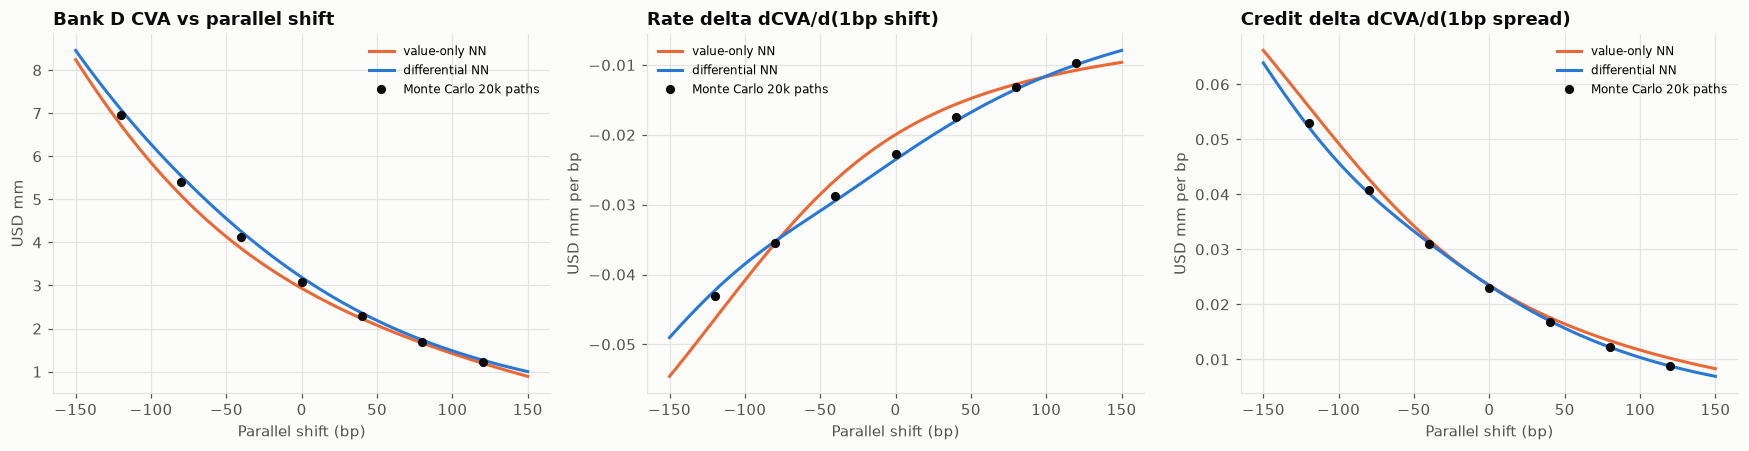

CVA today               3.19
shift (delta × move)    1.18
sigma (delta × move)    0.60
spread (delta × move)   0.74
cross / convexity       0.52
CVA after move          6.23
dtype: float64

In [17]:
# --- Chart 5: CVA and its rate delta along the curve-shift axis
line = np.c_[
    np.linspace(-0.015, 0.015, 121),
    np.full(121, SIGMA_HW),
    np.full(121, spread_today),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for net, name, color in [
    (net_value, "value-only NN", PALETTE[1]),
    (net_diff, "differential NN", PALETTE[0]),
]:
    pv, pg = net_cva_and_greeks(net, line)
    axes[0].plot(line[:, 0] * 1e4, pv, color=color, label=name)
    axes[1].plot(line[:, 0] * 1e4, pg[:, 0] / 1e4, color=color, label=name)
    axes[2].plot(line[:, 0] * 1e4, pg[:, 2] / 1e4, color=color, label=name)
for ax, vals, title, unit in [
    (axes[0], truth_v[:7], f"{cp_dml} CVA vs parallel shift", "USD mm"),
    (
        axes[1],
        truth_g[:7, 0] / 1e4,
        "Rate delta dCVA/d(1bp shift)",
        "USD mm per bp",
    ),
    (
        axes[2],
        truth_g[:7, 2] / 1e4,
        "Credit delta dCVA/d(1bp spread)",
        "USD mm per bp",
    ),
]:
    ax.plot(
        test_shift * 1e4,
        vals,
        "o",
        color=INK,
        ms=5,
        label="Monte Carlo 20k paths",
    )
    ax.set_title(title)
    ax.set_xlabel("Parallel shift (bp)")
    ax.set_ylabel(unit)
    ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "05_differential_ml_cva_greeks")
plt.show()

# CVA explain for a market move, done instantly with the differential network
v0, g0 = net_cva_and_greeks(
    net_diff, np.array([[0.0, SIGMA_HW, spread_today]])
)
# −50bp, vol +20%, spread +30%
move = np.array([-0.0050, SIGMA_HW * 0.20, spread_today * 0.30])
v1, _ = net_cva_and_greeks(
    net_diff, np.array([[move[0], SIGMA_HW + move[1], spread_today + move[2]]])
)
explain = pd.Series({
    "CVA today": v0[0],
    **{f"{n} (delta × move)": g0[0, i] * move[i] for i, n in enumerate(NAMES)},
    "cross / convexity": v1[0] - v0[0] - (g0[0] * move).sum(),
    "CVA after move": v1[0],
})
xva.to_csv(OUT_DIR / "xva_by_counterparty.csv")
desk_xva.to_csv(OUT_DIR / "xva_by_desk.csv")
alloc.to_csv(OUT_DIR / "cva_allocation_by_trade.csv", index=False)
wwr_mult.to_csv(OUT_DIR / "wrong_way_risk_multipliers.csv")
dml_scores.to_csv(OUT_DIR / "differential_ml_scores.csv")
explain.round(4)

## 9. Reading the results and limitations

These figures come from the run of 16 October 2026.

**The total bill.** XVA for the whole book is about −27mm: CVA −7.8mm, DVA +5.2mm, FVA roughly flat (5 bp funding spread) and **KVA −24mm**.

For long-dated swaps without collateral, the cost of holding capital, mostly BA-CVA capital, is larger than the expected loss itself. That is the economic case for CSAs and for CVA hedging, which the full version of BA-CVA recognises.

**Where it sits.** Bank D (BBB, 29-year receiver) carries 42% of CVA and half of the total XVA. Bank B's book is 45mm out of the money for the MDB, so its CVA is small, and its DVA and FBA make the total slightly positive.

**Wrong-way risk is large here.** The MDB receives fixed from every bank (these are issuance hedges), so exposure peaks when rates fall.

If bank credit worsens in those scenarios ($\beta=-0.5$), CVA rises 1.7–2.2×; at $\beta=-1$ it rises 2.3–3.8×. A modest correlation matters more than a one-notch rating change.

**Allocation.** Euler and Shapley both add up exactly to the netting-set CVA. Stand-alone CVA overstates the total by 1% for Bank A (all receivers) and by 725% for Bank B, whose trades largely offset each other.

At trade level, Euler and Shapley can differ by up to 0.8mm on Bank D. Euler prices the last unit of each trade, while Shapley averages over the order in which trades arrive, so it shares the netting benefit more evenly.

Hedging trades (pay-fixed against a receiver book) get **negative** Euler charges, which is a credit to the desk. The ALM desk earns about +4mm of XVA benefit, while the long-dated client book is charged about −26mm.

**Differential ML works as promised.** The training labels are single-path CVAs whose noise is more than twice their mean. Even so, the differential network gets CVA within about 4%, and the rate, vol and credit deltas within 2–6%, of 20,000-path Monte Carlo.

A network trained on values alone misses the vol and credit deltas by 15–19%. One evaluation takes microseconds, against about 21 seconds for Monte Carlo.

The PyTorch pricer matches the NumPy engine within the combined Monte Carlo error of two independent 5,000-path runs (±0.22mm).

**CVA explain.** If rates move −50 bp, vol rises 20% and spreads widen 30%, Bank D's CVA roughly doubles. The network splits that change into rate, vol and credit effects plus a small cross term, instantly.

**Runtime.** About 10 minutes on CPU, mostly the 20,000-path test grid and network training.

**Limitations**

- Credit spreads come from corporate bond indices by rating, not bank CDS, and they are flat in maturity. Recovery is fixed at 40%.
- There is no collateral. A CSA would shrink CVA and FVA and add MVA through initial margin.
- DVA and FVA ignore default correlation between the bank and the MDB (no first-to-default).
- KVA uses simplified capital: standardised bank risk weights on an IMM-style EAD and reduced BA-CVA, with no CVA hedges recognised. It ignores the output floor and the leverage ratio.
- The differential network is only valid inside its training box, and it is trained for one netting set. A production desk would train one per netting set or add trade features.

## References

### Finance and regulation

- Basel Committee on Banking Supervision. (2014). *The standardised approach for measuring counterparty credit risk exposures*. Bank for International Settlements. https://www.bis.org/publ/bcbs279.htm
- Basel Committee on Banking Supervision. (2020). *Targeted revisions to the credit valuation adjustment risk framework*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d507.htm
- Brigo, D., Morini, M., & Pallavicini, A. (2013). *Counterparty credit risk, collateral and funding: With pricing cases for all asset classes*. Wiley. https://doi.org/10.1002/9781118818589
- Green, A., Kenyon, C., & Dennis, C. (2014). KVA: Capital valuation adjustment by replication. *Risk, 27*(12). https://arxiv.org/abs/1405.0515
- Hull, J., & White, A. (1990). Pricing interest-rate-derivative securities. *The Review of Financial Studies, 3*(4), 573–592. https://doi.org/10.1093/rfs/3.4.573
- Hull, J., & White, A. (2012). CVA and wrong-way risk. *Financial Analysts Journal, 68*(5), 58–69. https://doi.org/10.2469/faj.v68.n5.6
- Tasche, D. (2008). Capital allocation to business units and sub-portfolios: The Euler principle. In A. Resti (Ed.), *Pillar II in the new Basel Accord*. Risk Books. https://arxiv.org/abs/0708.2542

### Machine learning and deep learning

- Huge, B., & Savine, A. (2020). Differential machine learning. *arXiv*. https://arxiv.org/abs/2005.02347
- Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., … Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*. https://arxiv.org/abs/1912.01703
- Shapley, L. S. (1953). A value for n-person games. In H. W. Kuhn & A. W. Tucker (Eds.), *Contributions to the theory of games II* (pp. 307–317). Princeton University Press. https://doi.org/10.1515/9781400881970-018